## Setup

In [95]:
!pip install segmentation-models-pytorch scipy opencv-python matplotlib -q

In [96]:
import os
import glob
import re
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt

## Config
Edit paths below to match your Kaggle input/checkpoint locations. Run `!find /kaggle/input -maxdepth 4` first if unsure of the real dataset path (Section 11).

In [97]:
# Test set folders (untouched until now, per project guide Section 3)
TEST_IMG_DIR = "/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset/Testing/testset_images"
TEST_MASK_DIR = "/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset/Testing/testset_masks"

# Checkpoints for each run (edit paths to wherever you unzipped results.zip)
CHECKPOINTS = {
    "Run1_UNetPP_noAug": "/kaggle/input/datasets/zakariaassadiki/vessels-results/kaggle/working/checkpoints/vessel_run1_unetplusplus_augOFF.pth",
    "Run2_UNetPP_aug":   "/kaggle/input/datasets/zakariaassadiki/vessels-results/kaggle/working/checkpoints/vessel_run2_unetplusplus_augON.pth",
    "Run3_AttnUNet_aug": "/kaggle/input/datasets/zakariaassadiki/vessels-results/kaggle/working/checkpoints/vessel_run3_attentionunet_augON.pth",
}

OUT_DIR = "/kaggle/working/inference_results"
os.makedirs(OUT_DIR, exist_ok=True)

NUM_CLASSES = 5
PATCH_SIZE = 256
UM_PER_PIXEL = 0.227 * 4  # native 0.227 um/px * 4x downsample factor -> ~0.908 um/px

CLASS_NAMES = ["background", "portal_vein", "central_vein", "artery", "bile_duct"]

# Pure RGB colors used in the raw masks.
# IMPORTANT: background is WHITE here, not black. Confirmed via the diagnostic
# cell above by direct pixel inspection of the actual TEST masks -- the test set
# uses a DIFFERENT background encoding than the training set (which was black,
# per Section 1 of the project guide). Portal vein / central vein / artery / bile
# duct pure colors are unchanged (blue/green/red/purple), only background flipped.
# This mismatch (assuming train's convention applied to test) was the root cause
# of the catastrophic Dice scores in the first inference attempt -- every white
# background pixel was getting matched to purple (bile duct), its nearest neighbor
# among the training-set colors, corrupting the ground truth for every class.
# Document this discrepancy as a data-quality note in the report (Section 14 style).
CLASS_COLORS_RGB = np.array([
    [255, 255, 255],  # background (WHITE in test set -- verified, differs from train)
    [0,   0,   255],  # portal vein (blue)
    [0,   255, 0],    # central vein (green)
    [255, 0,   0],    # artery (red)
    [128, 0,   128],  # bile duct (purple)
], dtype=np.float32)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_VIS_SAMPLES = 6  # how many test patches to show in the visual comparison grid

# ImageNet normalization -- CONFIRMED from training script (Cell 6, A.Normalize applied identically to aug ON/OFF and eval transforms). Every image
# the model ever saw was normalized this way; inference must match exactly.
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

## Data loading
Pairs `patch_N.tiff` with `mask_N.tiff`, resizes image (area) and mask (nearest) to 256x256 *before* RGB->class-index color-matching, mirroring the fixed training pipeline (Section 2).

In [98]:
def list_pairs(img_dir, mask_dir):
    """Pair patch_N.tiff <-> mask_N.tiff by numeric id, as in training."""
    img_paths = glob.glob(os.path.join(img_dir, "patch_*.tiff"))
    pairs = []
    for p in img_paths:
        m = re.search(r"patch_(\d+)\.tiff$", os.path.basename(p))
        if not m:
            continue
        idx = m.group(1)
        mask_path = os.path.join(mask_dir, f"mask_{idx}.tiff")
        if os.path.exists(mask_path):
            pairs.append((p, mask_path))
    pairs.sort(key=lambda x: int(re.search(r"(\d+)", os.path.basename(x[0])).group(1)))
    return pairs


def rgb_mask_to_class_index(mask_rgb_small):
    """Nearest-color classification. Done AFTER resizing (Section 2 perf fix) --
    matters for correctness too: resizing first avoids picking up novel anti-aliased
    blend colors that would not match any of the 5 pure classes as cleanly."""
    h, w, _ = mask_rgb_small.shape
    flat = mask_rgb_small.reshape(-1, 3).astype(np.float32)
    dists = np.linalg.norm(flat[:, None, :] - CLASS_COLORS_RGB[None, :, :], axis=2)
    class_idx = np.argmin(dists, axis=1)
    return class_idx.reshape(h, w)


def load_pair(img_path, mask_path):
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_COLOR)
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

    # Resize FIRST (image: area interp, mask: nearest), then color-match on the
    # small array -- same order as the fixed training pipeline (Section 2).
    img_small = cv2.resize(img, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_AREA)
    mask_small_rgb = cv2.resize(mask, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_NEAREST)

    mask_class = rgb_mask_to_class_index(mask_small_rgb)
    return img_small, mask_class

## Diagnostic: inspect ACTUAL test mask colors
**Run this before trusting any metrics above.** The GT panels in your visual grids show purple as the dominant color where background should be -- meaning the test masks likely use a different color convention than the training masks did (e.g. white background instead of black). If so, `rgb_mask_to_class_index` misclassifies every background pixel as bile duct (purple is white's nearest neighbor among the 5 known colors), which would tank every class's Dice score, including background. Don't assume -- confirm by direct pixel inspection, same as Section 16 of the project guide.

In [99]:
import collections

# Always recompute fresh -- don't trust a possibly-stale `pairs` variable left
# over from an earlier run with different (e.g. placeholder) paths.
diag_pairs = list_pairs(TEST_IMG_DIR, TEST_MASK_DIR)
print(f"Found {len(diag_pairs)} pairs using current TEST_IMG_DIR / TEST_MASK_DIR.")
if len(diag_pairs) == 0:
    raise RuntimeError(
        "No pairs found. Double-check TEST_IMG_DIR and TEST_MASK_DIR point to the "
        "actual folders (run !find /kaggle/input -maxdepth 6 -iname 'testset_images' "
        "if unsure), and that this cell ran AFTER the Config cell with the real paths."
    )

sample_mask_path = diag_pairs[0][1]
raw_mask = cv2.imread(sample_mask_path, cv2.IMREAD_COLOR)
raw_mask = cv2.cvtColor(raw_mask, cv2.COLOR_BGR2RGB)

print(f"Inspecting: {sample_mask_path}")
print(f"Shape: {raw_mask.shape}, dtype: {raw_mask.dtype}")

flat = raw_mask.reshape(-1, 3)
counts = collections.Counter(map(tuple, flat))
print("\nTop 10 most common raw RGB colors in this test mask (color: pixel_count):")
for color, cnt in counts.most_common(10):
    print(f"  {color}: {cnt}")

# Check a few more masks to see if the dominant "background-like" color is consistent
print("\n--- Checking dominant color across 5 sample test masks ---")
for img_p, mask_p in diag_pairs[:5]:
    m = cv2.cvtColor(cv2.imread(mask_p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    dom_color, dom_count = collections.Counter(map(tuple, m.reshape(-1, 3))).most_common(1)[0]
    frac = dom_count / (m.shape[0] * m.shape[1])
    print(f"  {os.path.basename(mask_p)}: dominant color = {dom_color} ({frac:.1%} of pixels)")

Found 728 pairs using current TEST_IMG_DIR / TEST_MASK_DIR.
Inspecting: /kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset/Testing/testset_masks/mask_1.tiff
Shape: (1024, 1024, 3), dtype: uint8

Top 10 most common raw RGB colors in this test mask (color: pixel_count):
  (np.uint8(255), np.uint8(255), np.uint8(255)): 906889
  (np.uint8(0), np.uint8(255), np.uint8(0)): 136574
  (np.uint8(253), np.uint8(255), np.uint8(253)): 475
  (np.uint8(254), np.uint8(255), np.uint8(254)): 309
  (np.uint8(11), np.uint8(255), np.uint8(11)): 298
  (np.uint8(1), np.uint8(255), np.uint8(1)): 232
  (np.uint8(2), np.uint8(255), np.uint8(2)): 231
  (np.uint8(248), np.uint8(255), np.uint8(248)): 230
  (np.uint8(252), np.uint8(255), np.uint8(252)): 196
  (np.uint8(5), np.uint8(255), np.uint8(5)): 172

--- Checking dominant color across 5 sample test masks ---
  mask_1.tiff: dominant color = (np.uint8(255), np.uint8(255), np.uint8(255)) (86.5% of pixels)
  mask_2.tiff: dominant color = (

## Models
**Caveat:** `AttentionUNet` below is a reimplementation of Oktay et al. 2018 (attention gates on every skip connection). The first load attempt against the real Run 3 checkpoint failed (wrong gate-submodule names, wrong base channel width) -- fixed below using the actual keys/shapes reported in that error. If it still fails, there are further structural differences and we need your real training-time class pasted in here instead of continuing to guess.

In [100]:
def build_unetpp():
    import segmentation_models_pytorch as smp
    return smp.UnetPlusPlus(
        encoder_name="resnet34",
        encoder_weights=None,  # loading trained weights next; no need to fetch imagenet
        classes=NUM_CLASSES,
    )


class AttentionGate(nn.Module):
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.BatchNorm2d(f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class AttentionUNet(nn.Module):
    """Oktay et al. 2018. No pretrained encoder (matches Run 3 training config --
    Section 4 / 14 caveat).

    NOTE: base=32 and W_g/W_x naming were reverse-engineered from the Run 3
    checkpoint's actual state_dict keys/shapes after the first load attempt failed.
    If load_state_dict still errors after this fix, there are further structural
    differences from this reimplementation -- at that point we need your real
    training-time class pasted in rather than guessing further.
    """

    def __init__(self, in_ch=3, num_classes=5, base=32):
        super().__init__()
        chs = [base, base * 2, base * 4, base * 8, base * 16]
        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(in_ch, chs[0])
        self.enc2 = ConvBlock(chs[0], chs[1])
        self.enc3 = ConvBlock(chs[1], chs[2])
        self.enc4 = ConvBlock(chs[2], chs[3])
        self.bottleneck = ConvBlock(chs[3], chs[4])

        self.up4 = nn.ConvTranspose2d(chs[4], chs[3], 2, stride=2)
        self.att4 = AttentionGate(chs[3], chs[3], chs[3] // 2)
        self.dec4 = ConvBlock(chs[4], chs[3])

        self.up3 = nn.ConvTranspose2d(chs[3], chs[2], 2, stride=2)
        self.att3 = AttentionGate(chs[2], chs[2], chs[2] // 2)
        self.dec3 = ConvBlock(chs[3], chs[2])

        self.up2 = nn.ConvTranspose2d(chs[2], chs[1], 2, stride=2)
        self.att2 = AttentionGate(chs[1], chs[1], chs[1] // 2)
        self.dec2 = ConvBlock(chs[2], chs[1])

        self.up1 = nn.ConvTranspose2d(chs[1], chs[0], 2, stride=2)
        self.att1 = AttentionGate(chs[0], chs[0], chs[0] // 2)
        self.dec1 = ConvBlock(chs[1], chs[0])

        self.out_conv = nn.Conv2d(chs[0], num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        e4a = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4a], dim=1))

        d3 = self.up3(d4)
        e3a = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3a], dim=1))

        d2 = self.up2(d3)
        e2a = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2a], dim=1))

        d1 = self.up1(d2)
        e1a = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1a], dim=1))

        return self.out_conv(d1)


def build_model_for_run(run_name):
    if "AttnUNet" in run_name:
        return AttentionUNet(in_ch=3, num_classes=NUM_CLASSES)
    return build_unetpp()


def load_checkpoint(model, ckpt_path):
    state = torch.load(ckpt_path, map_location=DEVICE)
    # handle both raw state_dict and {'model_state_dict': ...} style checkpoints
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    model.load_state_dict(state)
    model.to(DEVICE)
    model.eval()
    return model

## Metrics
Dice, IoU, TPR from an accumulated confusion matrix; ASSD (in microns) per class via boundary distance transforms.

In [101]:
def per_class_confusion(pred, gt, num_classes):
    """Returns confusion matrix [gt, pred], accumulated across a batch of patches."""
    mask = (gt >= 0) & (gt < num_classes)
    idx = num_classes * gt[mask].astype(int) + pred[mask].astype(int)
    cm = np.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return cm


def dice_iou_tpr_from_confusion(cm):
    """cm[i, j] = count of pixels with gt class i predicted as class j."""
    num_classes = cm.shape[0]
    dice = np.zeros(num_classes)
    iou = np.zeros(num_classes)
    tpr = np.zeros(num_classes)
    for c in range(num_classes):
        tp = cm[c, c]
        fn = cm[c, :].sum() - tp
        fp = cm[:, c].sum() - tp
        denom_dice = 2 * tp + fp + fn
        denom_iou = tp + fp + fn
        dice[c] = (2 * tp / denom_dice) if denom_dice > 0 else np.nan
        iou[c] = (tp / denom_iou) if denom_iou > 0 else np.nan
        tpr[c] = (tp / (tp + fn)) if (tp + fn) > 0 else np.nan
    return dice, iou, tpr


def assd_binary(pred_bin, gt_bin, um_per_pixel):
    """Average Symmetric Surface Distance for one binary class mask, in microns.
    Returns NaN if either mask is empty (no boundary to measure)."""
    if pred_bin.sum() == 0 or gt_bin.sum() == 0:
        return np.nan

    pred_edt = distance_transform_edt(~pred_bin)
    gt_edt = distance_transform_edt(~gt_bin)

    pred_boundary = pred_bin & ~cv2.erode(pred_bin.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    gt_boundary = gt_bin & ~cv2.erode(gt_bin.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)

    d_pred_to_gt = gt_edt[pred_boundary]
    d_gt_to_pred = pred_edt[gt_boundary]

    if len(d_pred_to_gt) == 0 or len(d_gt_to_pred) == 0:
        return np.nan

    assd_px = (d_pred_to_gt.sum() + d_gt_to_pred.sum()) / (len(d_pred_to_gt) + len(d_gt_to_pred))
    return assd_px * um_per_pixel

## Inference loop
Runs a model over all test pairs, accumulates the confusion matrix + ASSD, and keeps the first `N_VIS_SAMPLES` patches for the visual comparison grid.

In [102]:
def run_inference_for_model(run_name, ckpt_path, pairs):
    model = build_model_for_run(run_name)
    model = load_checkpoint(model, ckpt_path)

    cm_total = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    assd_accum = {c: [] for c in range(NUM_CLASSES)}

    vis_samples = []  # (img, gt_class, pred_class) for the first N_VIS_SAMPLES pairs

    with torch.no_grad():
        for i, (img_path, mask_path) in enumerate(pairs):
            img_small, gt_class = load_pair(img_path, mask_path)

            # Normalize exactly like training: scale to [0,1], then ImageNet mean/std
            img_norm = (img_small.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
            x = torch.from_numpy(img_norm).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE)
            logits = model(x)
            pred_class = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

            cm_total += per_class_confusion(pred_class, gt_class, NUM_CLASSES)

            for c in range(NUM_CLASSES):
                pred_bin = pred_class == c
                gt_bin = gt_class == c
                d = assd_binary(pred_bin, gt_bin, UM_PER_PIXEL)
                if not np.isnan(d):
                    assd_accum[c].append(d)

            if len(vis_samples) < N_VIS_SAMPLES:
                vis_samples.append((img_small, gt_class, pred_class))

    dice, iou, tpr = dice_iou_tpr_from_confusion(cm_total)
    assd = np.array([np.mean(assd_accum[c]) if assd_accum[c] else np.nan for c in range(NUM_CLASSES)])

    results = {
        "run_name": run_name,
        "confusion_matrix": cm_total,
        "dice": dice,
        "iou": iou,
        "tpr": tpr,
        "assd_um": assd,
    }
    return results, vis_samples

## Visualization + reporting helpers

In [103]:
DISPLAY_COLORS_RGB = CLASS_COLORS_RGB.copy()
DISPLAY_COLORS_RGB[0] = [0, 0, 0]  # render background as black in plots for contrast
# (classification/matching still uses the real white background color above --
# this override is display-only, doesn't affect metrics)


def class_index_to_rgb(class_map):
    return DISPLAY_COLORS_RGB[class_map].astype(np.uint8)


def save_visual_grid(run_name, vis_samples, out_dir):
    n = len(vis_samples)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    if n == 1:
        axes = axes[None, :]

    col_titles = ["Original", "Ground Truth", "Prediction"]
    for row, (img, gt, pred) in enumerate(vis_samples):
        gt_rgb = class_index_to_rgb(gt)
        pred_rgb = class_index_to_rgb(pred)
        for col, arr in enumerate([img, gt_rgb, pred_rgb]):
            ax = axes[row, col]
            ax.imshow(arr)
            ax.axis("off")
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)

    fig.suptitle(run_name, fontsize=14)
    fig.tight_layout()
    out_path = os.path.join(out_dir, f"{run_name}_visual_comparison.png")
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved visual comparison: {out_path}")


def print_metrics_table(results):
    print(f"\n=== {results['run_name']} ===")
    print(f"{'class':<14}{'dice':>8}{'iou':>8}{'tpr':>8}{'assd(um)':>10}")
    for c, name in enumerate(CLASS_NAMES):
        print(f"{name:<14}{results['dice'][c]:>8.3f}{results['iou'][c]:>8.3f}"
              f"{results['tpr'][c]:>8.3f}{results['assd_um'][c]:>10.2f}")
    print("confusion matrix [rows=gt, cols=pred]:")
    print(results["confusion_matrix"])

## Run
Loads test pairs, then runs inference + metrics + visual grid for each available checkpoint. Skips any run whose checkpoint path isn't found (edit `CHECKPOINTS` above if one is skipped unexpectedly).

In [104]:
pairs = list_pairs(TEST_IMG_DIR, TEST_MASK_DIR)
print(f"Found {len(pairs)} test patch/mask pairs.")
if len(pairs) == 0:
    raise RuntimeError("No test pairs found -- check TEST_IMG_DIR / TEST_MASK_DIR paths.")

Found 728 test patch/mask pairs.



Running inference: Run1_UNetPP_noAug

=== Run1_UNetPP_noAug ===
class             dice     iou     tpr  assd(um)
background       0.973   0.947   0.990      2.58
portal_vein      0.761   0.614   0.706     24.04
central_vein     0.806   0.674   0.905      2.83
artery           0.919   0.850   0.967      3.05
bile_duct        0.223   0.126   0.128     20.50
confusion matrix [rows=gt, cols=pred]:
[[42603656   145482   187497    52666    42663]
 [  208074   913687   168530     3455        0]
 [   56127    42311   941701        0        0]
 [    9494     4164        0   409856      301]
 [ 1669674     2149       75     2082   246564]]


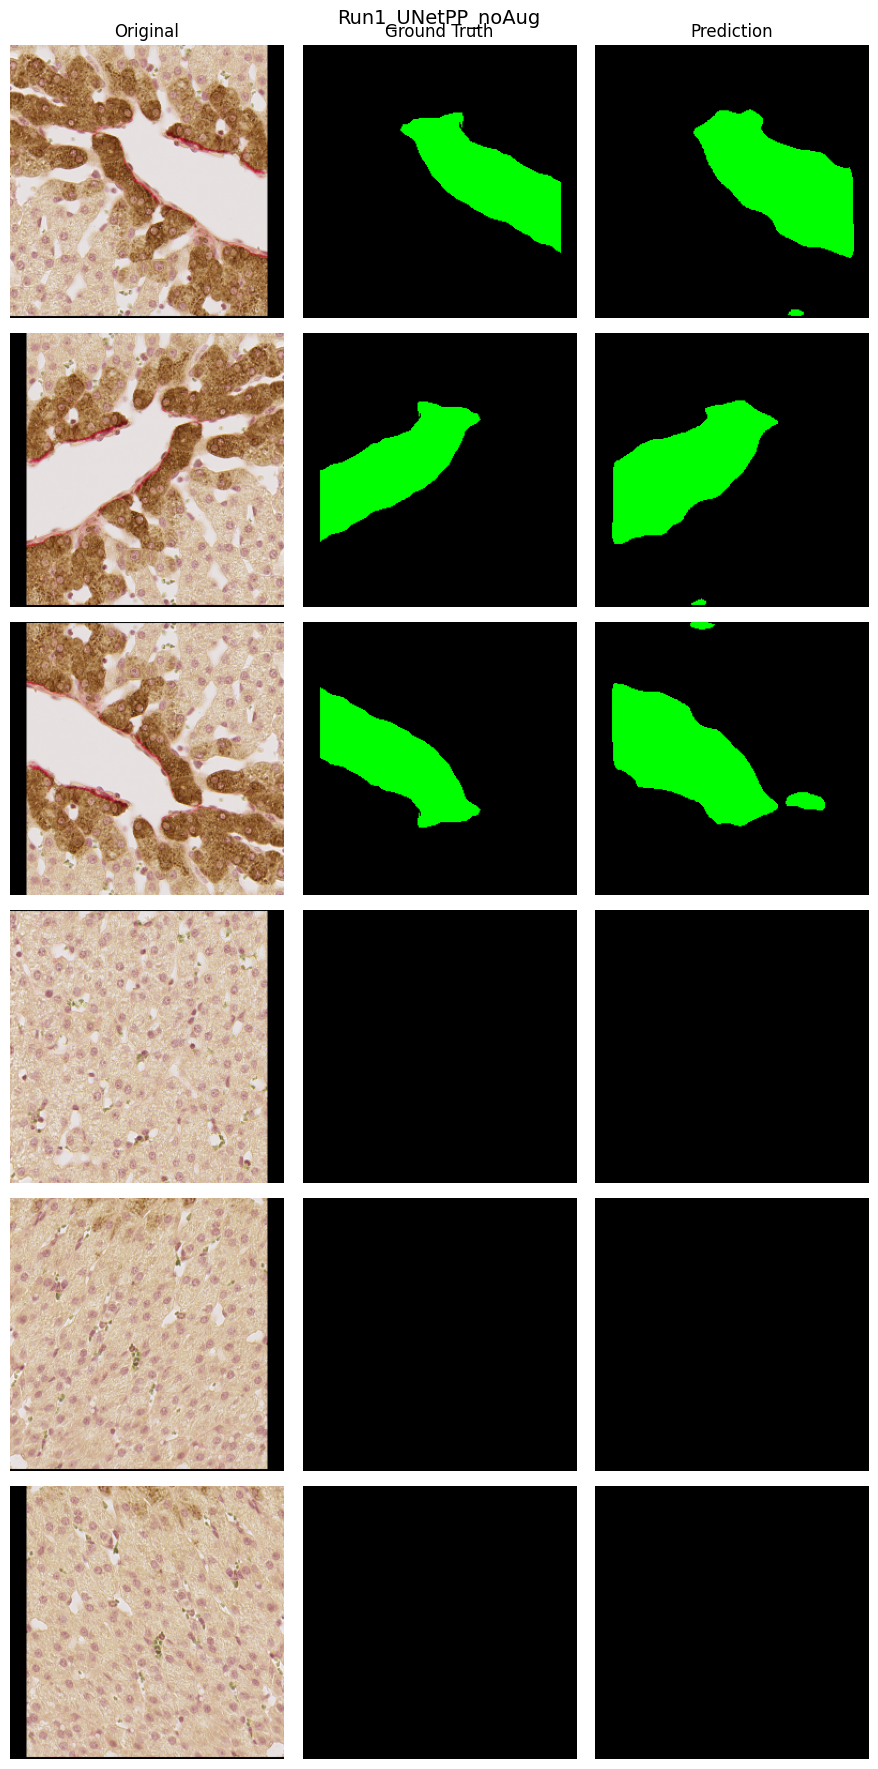

Saved visual comparison: /kaggle/working/inference_results/Run1_UNetPP_noAug_visual_comparison.png

Running inference: Run2_UNetPP_aug

=== Run2_UNetPP_aug ===
class             dice     iou     tpr  assd(um)
background       0.974   0.950   0.992      2.30
portal_vein      0.720   0.563   0.594     20.26
central_vein     0.776   0.634   0.949      2.42
artery           0.920   0.851   0.939      2.31
bile_duct        0.231   0.131   0.134     24.32
confusion matrix [rows=gt, cols=pred]:
[[42691174    51606   200391    42379    46414]
 [  208007   768493   315993     1112      141]
 [   50546     2916   986677        0        0]
 [    8856    16759        0   397915      285]
 [ 1661999      809      148      174   257414]]


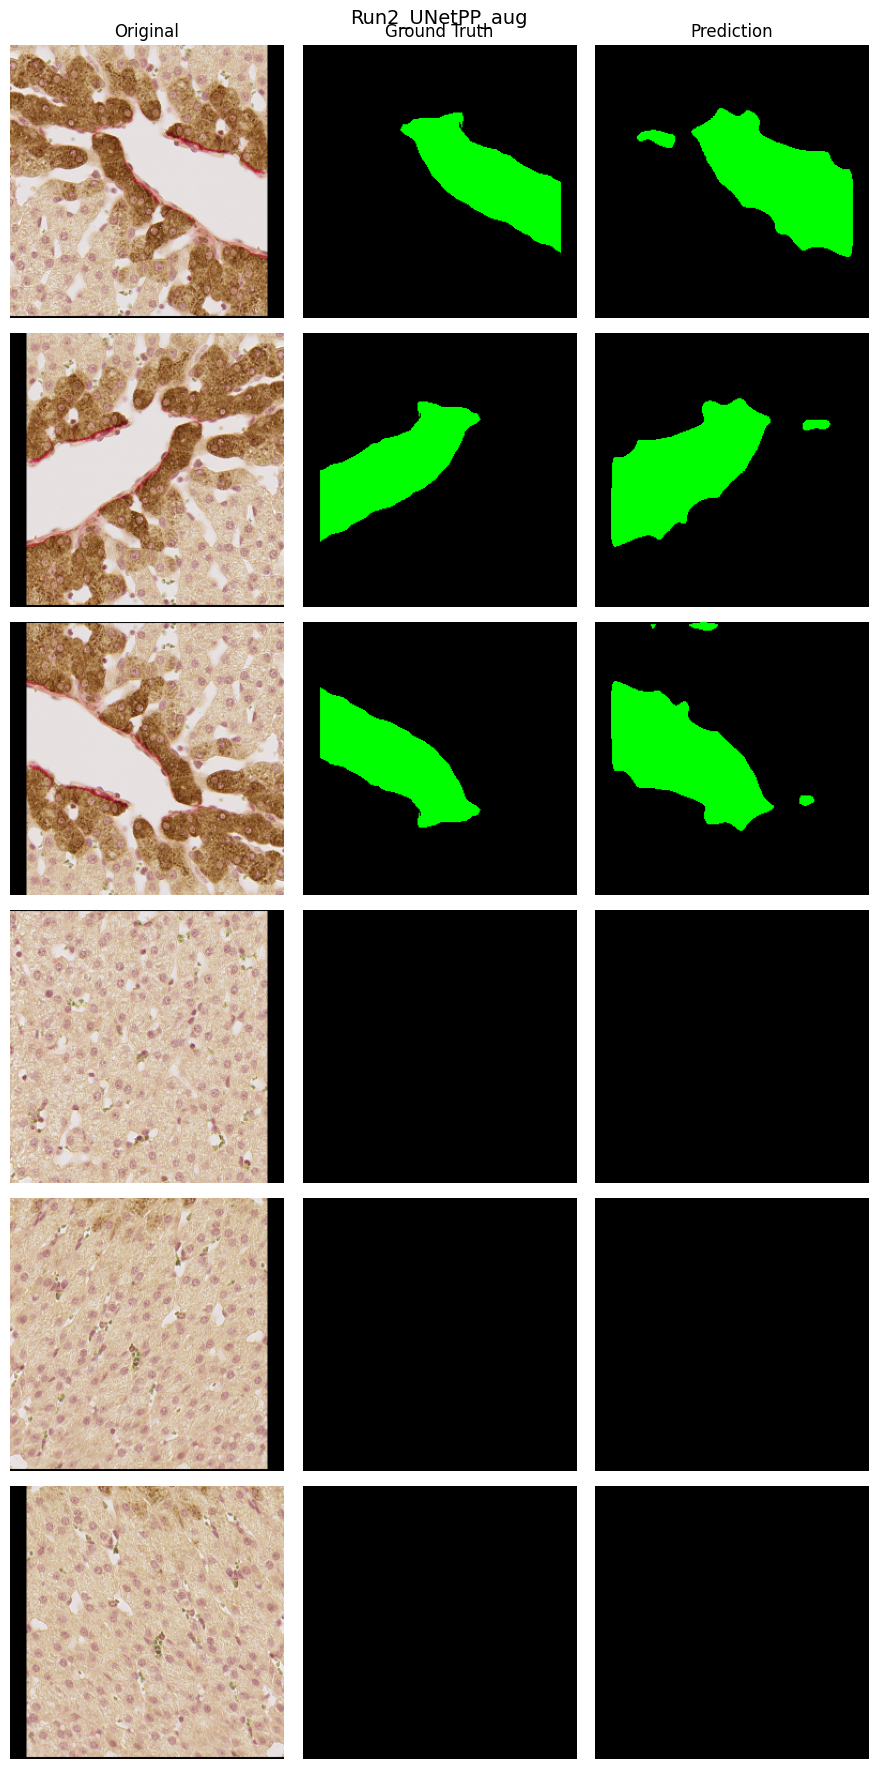

Saved visual comparison: /kaggle/working/inference_results/Run2_UNetPP_aug_visual_comparison.png

Running inference: Run3_AttnUNet_aug

=== Run3_AttnUNet_aug ===
class             dice     iou     tpr  assd(um)
background       0.972   0.946   0.993      2.85
portal_vein      0.617   0.447   0.486     22.93
central_vein     0.776   0.634   0.915      2.23
artery           0.914   0.842   0.901      5.44
bile_duct        0.199   0.110   0.112     30.30
confusion matrix [rows=gt, cols=pred]:
[[42748791    52946   180061    26490    23676]
 [  381957   629379   281110     1115      185]
 [   78231     9890   952018        0        0]
 [   20253    21711        0   381851        0]
 [ 1672929    31181      100     2044   214290]]


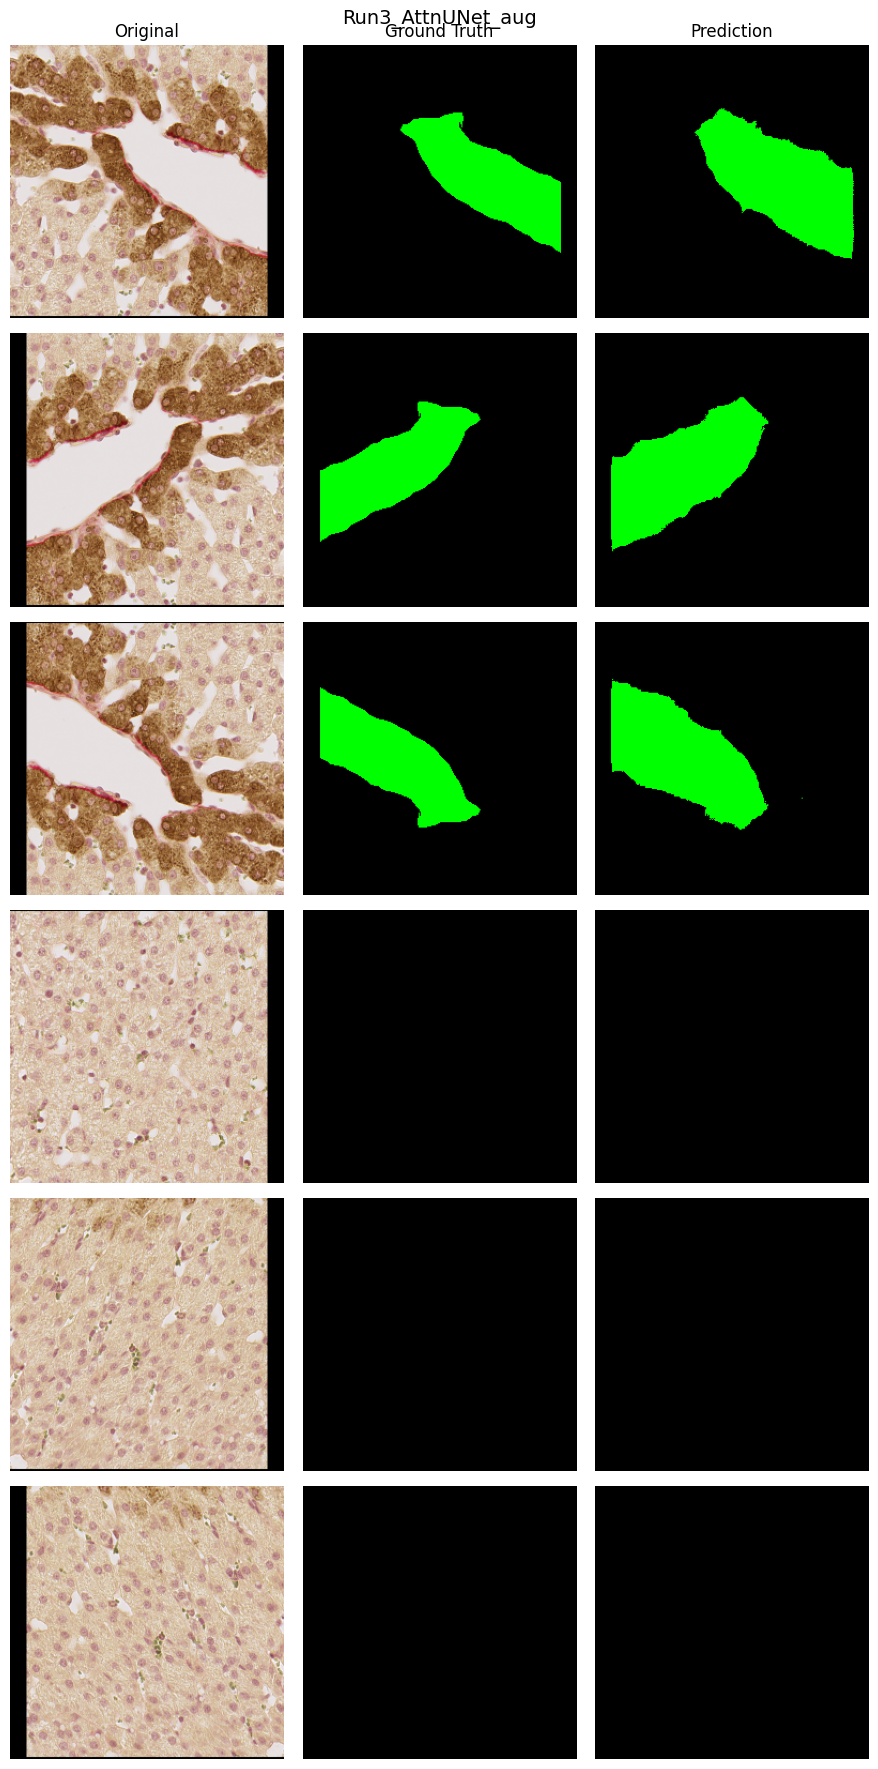

Saved visual comparison: /kaggle/working/inference_results/Run3_AttnUNet_aug_visual_comparison.png


In [105]:
all_results = []
for run_name, ckpt_path in CHECKPOINTS.items():
    if not os.path.exists(ckpt_path):
        print(f"[skip] checkpoint not found for {run_name}: {ckpt_path}")
        continue
    print(f"\nRunning inference: {run_name}")
    results, vis_samples = run_inference_for_model(run_name, ckpt_path, pairs)
    print_metrics_table(results)
    save_visual_grid(run_name, vis_samples, OUT_DIR)
    all_results.append(results)

## Random sample visual comparison
Unlike the grids saved during the main run (always the first N pairs in folder order), this samples a fresh random subset of the test set for a given checkpoint each time it's called. Set `seed` for reproducible picks, or leave as `None` for a different set each run.

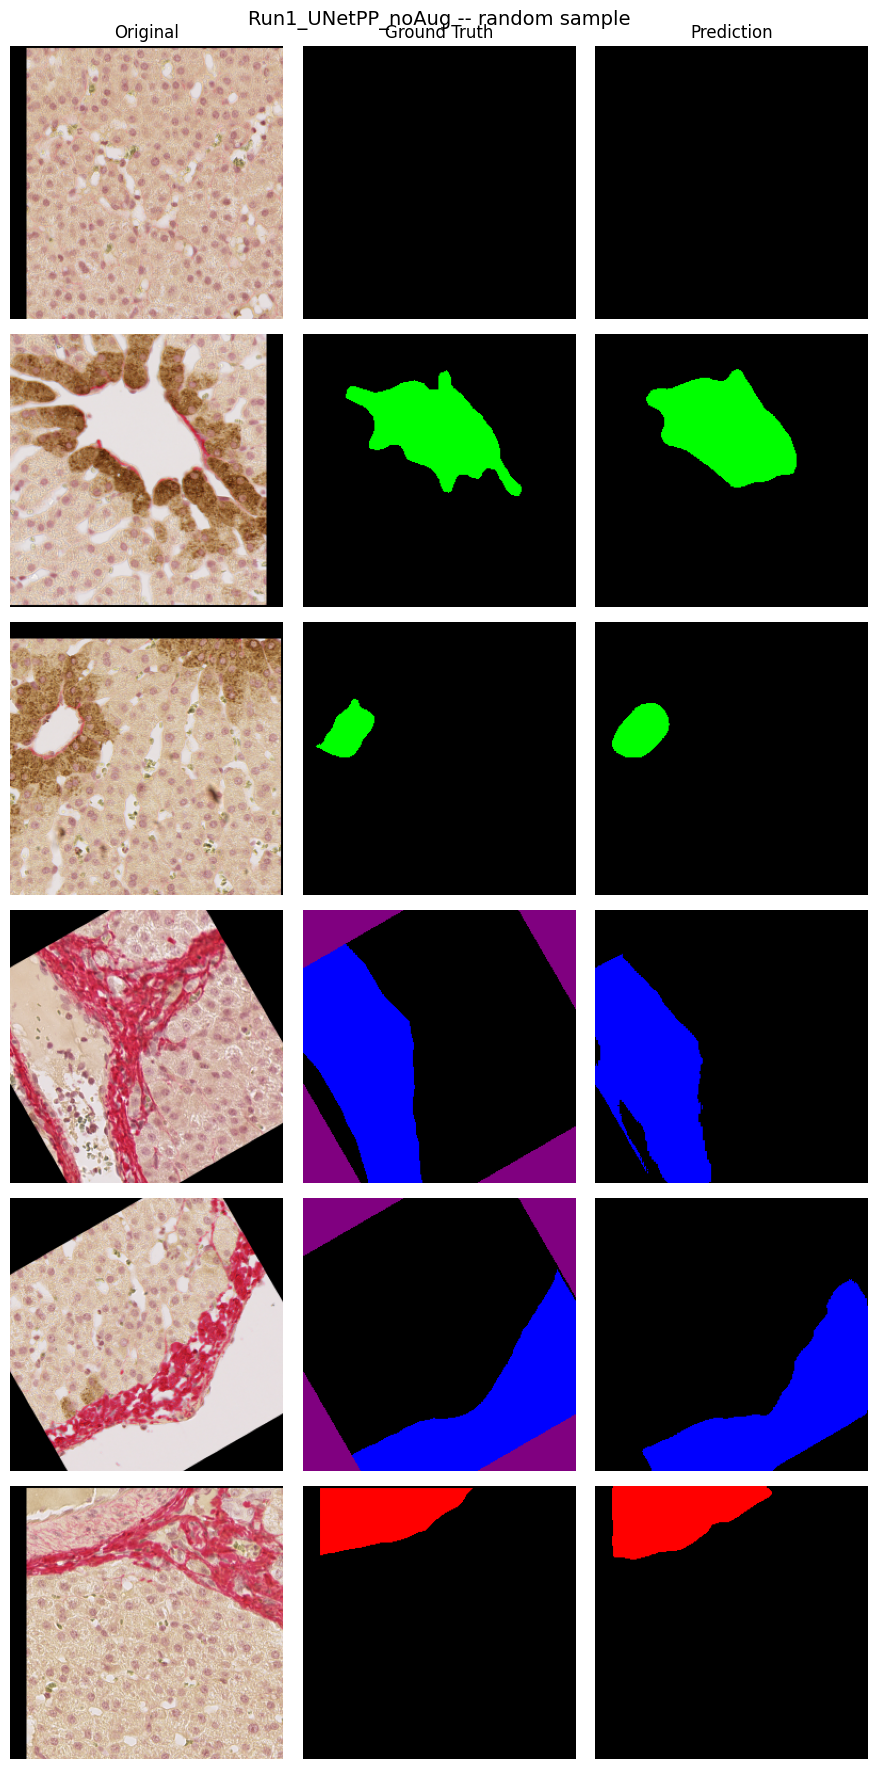

Saved: /kaggle/working/inference_results/Run1_UNetPP_noAug_random_comparison.png


In [121]:
import random

def visualize_random_samples(run_name, ckpt_path, pairs, n_samples=6, seed=None):
    rng = random.Random(seed)
    sample_pairs = rng.sample(pairs, min(n_samples, len(pairs)))

    model = build_model_for_run(run_name)
    model = load_checkpoint(model, ckpt_path)

    vis_samples = []
    with torch.no_grad():
        for img_path, mask_path in sample_pairs:
            img_small, gt_class = load_pair(img_path, mask_path)

            img_norm = (img_small.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
            x = torch.from_numpy(img_norm).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE)
            logits = model(x)
            pred_class = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

            vis_samples.append((img_small, gt_class, pred_class))

    fig, axes = plt.subplots(len(vis_samples), 3, figsize=(9, 3 * len(vis_samples)))
    if len(vis_samples) == 1:
        axes = axes[None, :]

    col_titles = ["Original", "Ground Truth", "Prediction"]
    for row, (img, gt, pred) in enumerate(vis_samples):
        gt_rgb = class_index_to_rgb(gt)
        pred_rgb = class_index_to_rgb(pred)
        for col, arr in enumerate([img, gt_rgb, pred_rgb]):
            ax = axes[row, col]
            ax.imshow(arr)
            ax.axis("off")
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)

    fig.suptitle(f"{run_name} -- random sample", fontsize=14)
    fig.tight_layout()
    out_path = os.path.join(OUT_DIR, f"{run_name}_random_comparison.png")
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {out_path}")


# Example usage -- change run_name / seed / n_samples as needed:
visualize_random_samples(
    run_name="Run1_UNetPP_noAug",
    ckpt_path=CHECKPOINTS["Run1_UNetPP_noAug"],
    pairs=pairs,
    n_samples=6,
    seed=None,  # set an int (e.g. 42) for reproducible sampling
)

## Save combined summary CSV

In [107]:
summary_path = os.path.join(OUT_DIR, "vessel_test_metrics_summary.csv")
with open(summary_path, "w") as f:
    f.write("run,class,dice,iou,tpr,assd_um\n")
    for r in all_results:
        for c, name in enumerate(CLASS_NAMES):
            f.write(f"{r['run_name']},{name},{r['dice'][c]:.4f},{r['iou'][c]:.4f},"
                    f"{r['tpr'][c]:.4f},{r['assd_um'][c]:.4f}\n")
print(f"Saved combined summary: {summary_path}")

Saved combined summary: /kaggle/working/inference_results/vessel_test_metrics_summary.csv


In [108]:
# Optional: zip everything for download, same pattern as training results (Section 11)
!cd /kaggle/working && zip -r inference_results.zip inference_results

updating: inference_results/ (stored 0%)
updating: inference_results/Run2_UNetPP_aug_visual_comparison.png (deflated 1%)
updating: inference_results/vessel_test_metrics_summary.csv (deflated 61%)
updating: inference_results/Run3_AttnUNet_aug_visual_comparison.png (deflated 1%)
updating: inference_results/Run1_UNetPP_noAug_visual_comparison.png (deflated 1%)
  adding: inference_results/Run1_UNetPP_noAug_random_comparison.png (deflated 1%)
